In [1]:
import sys
sys.path.append('..')

In [2]:
import numpy as np
from pathlib import Path
from src import simulate
from src import SV_configs
from src import utils
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns

In [ ]:
data_path = Path('../data/SV_search_constant_nosave_T12/')
constant_SV_search_tape_T12 = utils.load_dict(data_path / 'SV_search_tape.pkl')

In [ ]:
data_path = Path('../data/SV_search_exponential_nosave_T12/')
exp_SV_search_tape_T12 = utils.load_dict(data_path / 'SV_search_tape.pkl')

In [ ]:
data_path = Path('../data/SV_search_dirac_delta_nosave_T4/')
dirac_SV_search_tape_T4 = utils.load_dict(data_path / 'SV_search_tape.pkl')
data_path = Path('../data/SV_search_dirac_delta_nosave_T4_extendedrange/')
dirac_SV_search_tape_T4_ext = utils.load_dict(data_path / 'SV_search_tape.pkl')

/var/folders/88/p8znsc4j3wj6nq2cj7m_l4xr0000gn/T/ipykernel_20148/3247641123.py:17: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colormap = plt.cm.get_cmap('Oranges')
/var/folders/88/p8znsc4j3wj6nq2cj7m_l4xr0000gn/T/ipykernel_20148/3247641123.py:44: RuntimeWarning: divide by zero encountered in divide
  zero_loss_b = 1 / lambda_0


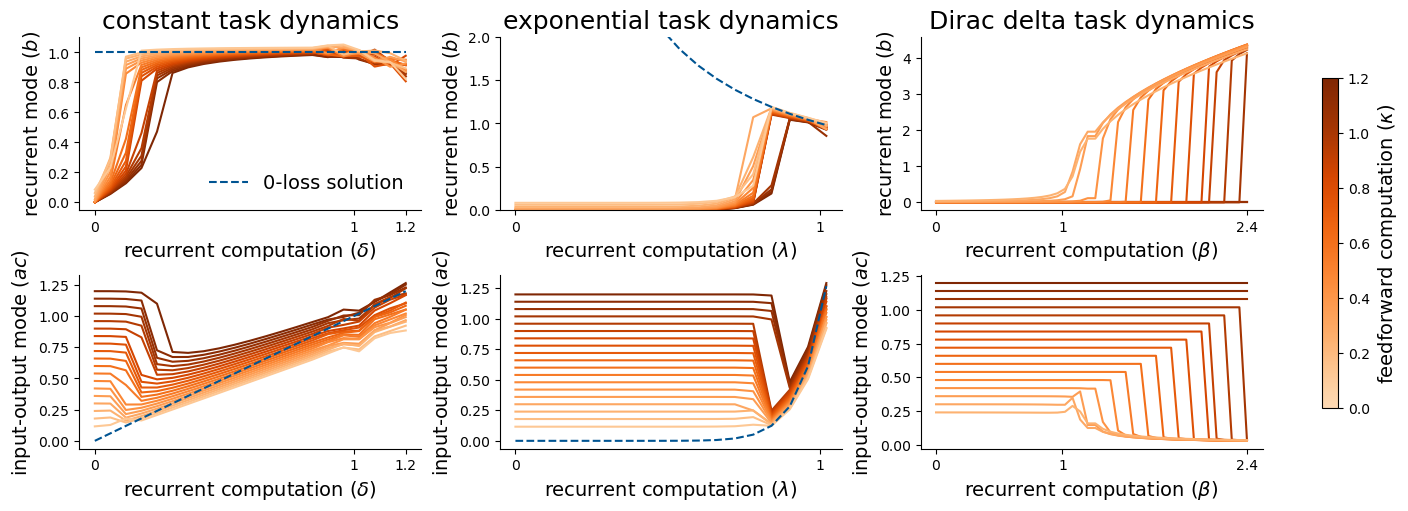

In [6]:
fig = plt.figure(figsize=(14,5), layout='constrained')
mosaic = """
abc
def
"""
axd = fig.subplots(nrows=2, ncols=3)
for ax in axd.flat: 
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)

cm = plt.cm.Oranges(np.linspace(1,0.2,21),alpha=1)
colormap = plt.cm.get_cmap('Oranges') 
axd.flat[0].set_prop_cycle('color', list(cm))
axd.flat[0].plot(np.fliplr(constant_SV_search_tape_T12.recurrent_modes_mean)[:,:-2])
axd.flat[0].set_ylabel(r'recurrent mode ($b$)', fontsize=14)
axd.flat[0].set_xlabel(r'recurrent computation ($\delta$)', fontsize=14)
axd.flat[0].set_xticks([0,16.666,20], [0,1,1.2])
axd.flat[0].plot(np.ones(21), ls='dashed',color='#005492', label='0-loss solution')
axd.flat[0].legend(frameon=False,fontsize=14)
axd.flat[0].set_title('constant task dynamics',fontsize=18)

axd.flat[3].set_prop_cycle('color', list(cm))
axd.flat[3].plot(np.fliplr(constant_SV_search_tape_T12.input_output_modes_mean)[:,:-2])
axd.flat[3].set_ylabel(r'input-output mode ($ac$)',fontsize=14)
axd.flat[3].set_xlabel(r'recurrent computation ($\delta$)',fontsize=14)
axd.flat[3].set_xticks([0,16.666,20], [0,1,1.2])
axd.flat[3].plot(np.linspace(0,1.2,21), ls='dashed',color='#005492')

axd.flat[1].set_prop_cycle('color', list(cm))
axd.flat[1].plot(np.fliplr(exp_SV_search_tape_T12.recurrent_modes_mean)[:18,:-2])
axd.flat[1].set_ylabel(r'recurrent mode ($b$)', fontsize=14)
axd.flat[1].set_xlabel(r'recurrent computation ($\lambda$)', fontsize=14)
axd.flat[1].set_xticks([0,16.666,20], [0,1,1.2])
lambda_0 = np.linspace(0,1.2,21)
zero_loss_b = 1 / lambda_0
axd.flat[1].plot(np.linspace(1,20,20)[:17], zero_loss_b[1:][:17], ls='dashed',color='#005492', label='0-loss solution')
axd.flat[1].set_ylim(0,2)
axd.flat[1].set_title('exponential task dynamics',fontsize=18)

axd.flat[4].set_prop_cycle('color', list(cm))
axd.flat[4].plot(np.fliplr(exp_SV_search_tape_T12.input_output_modes_mean[:18])[:,:-2])
axd.flat[4].set_ylabel(r'input-output mode ($ac$)', fontsize=14)
axd.flat[4].set_xlabel(r'recurrent computation ($\lambda$)', fontsize=14)
axd.flat[4].set_xticks([0,16.666,20], [0,1,1.2])
T = 12
axd.flat[4].plot((np.linspace(0,1.2,21)**T)[:18], ls='dashed',color='#005492')


axd.flat[2].set_prop_cycle('color', list(cm))
rec_modes_concat = np.concatenate((dirac_SV_search_tape_T4.recurrent_modes_mean, dirac_SV_search_tape_T4_ext.recurrent_modes_mean),axis=0)
axd.flat[2].plot(np.fliplr(rec_modes_concat)[:,:-4])
axd.flat[2].set_ylabel(r'recurrent mode ($b$)', fontsize=14)
axd.flat[2].set_xlabel(r'recurrent computation ($\beta$)', fontsize=14)
axd.flat[2].set_xticks([0,16.666,41], [0,1,2.4])
axd.flat[2].set_title('Dirac delta task dynamics',fontsize=18)

axd.flat[5].set_prop_cycle('color', list(cm))
inout_modes_concat = np.concatenate((dirac_SV_search_tape_T4.input_output_modes_mean, dirac_SV_search_tape_T4_ext.input_output_modes_mean),axis=0)
axd.flat[5].plot(np.fliplr(inout_modes_concat)[:,:-4])
axd.flat[5].set_ylabel(r'input-output mode ($ac$)', fontsize=14)
axd.flat[5].set_xlabel(r'recurrent computation ($\beta$)', fontsize=14)
axd.flat[5].set_xticks([0,16.666,41], [0,1,2.4])


normalizer = matplotlib.colors.Normalize(0, 1.2)
cm2 = plt.cm.Oranges(np.linspace(0.2,1,21),alpha=1)
im = matplotlib.cm.ScalarMappable(norm=normalizer, cmap=matplotlib.colors.LinearSegmentedColormap.from_list("",cm2))
cb = fig.colorbar(im, ax=axd.ravel().tolist(), shrink=0.8, label=r'feedforward computation ($\kappa$)')
cb.set_label(label=r'feedforward computation ($\kappa$)',size=14)
# fig.savefig('paper_figs/phase_transition.svg', dpi=300, transparent=True, bbox_inches='tight')
# fig.savefig('paper_figs/phase_transition.png', dpi=300, transparent=True, bbox_inches='tight')
# fig.savefig('paper_figs/phase_transition.pdf', dpi=300, transparent=True, bbox_inches='tight')